In [2]:
import gzip
import json

FILE_NAME = "nvdcve-2.0-2025.json.gz"

with gzip.open(FILE_NAME, "rt", encoding="utf-8") as f:
    data = json.load(f)

vulnerabilities = data["vulnerabilities"]

print("Dataset loaded successfully!")
print("Total CVE records:", len(vulnerabilities))

Dataset loaded successfully!
Total CVE records: 45095


In [3]:
cve = vulnerabilities[0]["cve"]

print("CVE ID:", cve["id"])
print("Published:", cve.get("published"))
print("Last Modified:", cve.get("lastModified"))

print("\nAvailable fields:")
print(cve.keys())

CVE ID: CVE-2025-0168
Published: 2025-01-01T14:15:23.590
Last Modified: 2026-06-17T08:26:00.070

Available fields:
dict_keys(['id', 'sourceIdentifier', 'published', 'lastModified', 'vulnStatus', 'cveTags', 'descriptions', 'affected', 'metrics', 'weaknesses', 'configurations', 'references'])


In [5]:

#vendors,products and available attributes
def extract_cve(item):

    cve = item["cve"]

  
    cve_id = cve["id"]

   
    description = ""

    for desc in cve.get("descriptions", []):
        if desc.get("lang") == "en":
            description = desc.get("value", "")
            break

    
    published = cve.get("published")
    last_modified = cve.get("lastModified")

    
    vendors = set()
    products = set()

    for config in cve.get("configurations", []):

        for node in config.get("nodes", []):

            for match in node.get("cpeMatch", []):

                criteria = match.get("criteria", "")

                parts = criteria.split(":")

                if len(parts) >= 5:

                    vendor = parts[3]
                    product = parts[4]

                    if vendor:
                        vendors.add(vendor)

                    if product:
                        products.add(product)

   
    cvss_score = None
    severity = "UNKNOWN"
    cvss_version = None

    metrics = cve.get("metrics", {})


    if metrics.get("cvssMetricV40"):

        metric = metrics["cvssMetricV40"][0]
        cvss = metric.get("cvssData", {})

        cvss_score = cvss.get("baseScore")
        severity = cvss.get("baseSeverity", "UNKNOWN")
        cvss_version = "4.0"

   
    elif metrics.get("cvssMetricV31"):

        metric = metrics["cvssMetricV31"][0]
        cvss = metric.get("cvssData", {})

        cvss_score = cvss.get("baseScore")
        severity = cvss.get("baseSeverity", "UNKNOWN")
        cvss_version = "3.1"

  
    elif metrics.get("cvssMetricV30"):

        metric = metrics["cvssMetricV30"][0]
        cvss = metric.get("cvssData", {})

        cvss_score = cvss.get("baseScore")
        severity = cvss.get("baseSeverity", "UNKNOWN")
        cvss_version = "3.0"

   
    return {
        "cve_id": cve_id,
        "description": description,
        "published": published,
        "last_modified": last_modified,
        "cvss_score": cvss_score,
        "severity": severity,
        "cvss_version": cvss_version,
        "vendors": sorted(vendors),
        "products": sorted(products)
    }

In [6]:
sample = extract_cve(vulnerabilities[0])

sample

{'cve_id': 'CVE-2025-0168',
 'description': 'A vulnerability classified as critical has been found in code-projects Job Recruitment 1.0. This affects an unknown part of the file /_parse/_feedback_system.php. The manipulation of the argument person leads to sql injection. It is possible to initiate the attack remotely. The exploit has been disclosed to the public and may be used.',
 'published': '2025-01-01T14:15:23.590',
 'last_modified': '2026-06-17T08:26:00.070',
 'cvss_score': 5.3,
 'severity': 'MEDIUM',
 'cvss_version': '4.0',
 'vendors': ['anisha'],
 'products': ['job_recruitment']}

In [7]:
documents = []

for item in vulnerabilities:

    document = extract_cve(item)

    documents.append(document)

print("Documents prepared:", len(documents))

Documents prepared: 45095


In [8]:
from pymongo import MongoClient

client = MongoClient("mongodb://localhost:27017/")

db = client["CVE_DB"]

collection = db["vulnerabilities"]

print("Connected to MongoDB successfully!")

Connected to MongoDB successfully!


In [9]:
collection.delete_many({})

result = collection.insert_many(documents)

print("Inserted documents:", len(result.inserted_ids))

Inserted documents: 45095


In [10]:
collection.create_index(
    "cve_id",
    unique=True
)

collection.create_index(
    "published"
)

collection.create_index(
    "severity"
)

collection.create_index(
    "cvss_score"
)

collection.create_index(
    "vendors"
)

collection.create_index(
    "products"
)

print("Indexes created successfully.")

Indexes created successfully.


In [12]:
sample = collection.find_one()

print(sample["cve_id"])

CVE-2025-0168


In [38]:
cve_id = input("Enter CVE ID: ")

result = collection.find_one({
    "cve_id": cve_id
})

if result:

    print("\nCVE ID:", result["cve_id"])
    print("Published:", result["published"])
    print("CVSS:", result["cvss_score"])
    print("Severity:", result["severity"])

    print("\nDescription:")
    print(result["description"])

else:

    print("CVE not found.")

CVE not found.


In [14]:
name = input("Enter vendor/product: ")

results = collection.find({
    "$or": [
        {
            "vendors": {
                "$regex": name,
                "$options": "i"
            }
        },
        {
            "products": {
                "$regex": name,
                "$options": "i"
            }
        }
    ]
})

count = 0

for result in results:

    print(
        result["cve_id"],
        "|",
        result["severity"],
        "|",
        result["cvss_score"]
    )

    count += 1

print("\nTotal matching CVEs:", count)

CVE-2025-11001 | HIGH | 7.8
CVE-2025-30411 | CRITICAL | 10.0
CVE-2025-30412 | CRITICAL | 10.0
CVE-2025-30416 | CRITICAL | 10.0
CVE-2025-11790 | MEDIUM | 4.4
CVE-2025-11791 | HIGH | 7.1
CVE-2025-11792 | HIGH | 7.3
CVE-2025-30413 | MEDIUM | 4.4
CVE-2025-5480 | HIGH | 7.8
CVE-2025-21122 | HIGH | 7.8
CVE-2025-21127 | HIGH | 7.8
CVE-2025-21128 | HIGH | 7.8
CVE-2025-21129 | HIGH | 7.8
CVE-2025-21130 | HIGH | 7.8
CVE-2025-21131 | HIGH | 7.8
CVE-2025-21132 | HIGH | 7.8
CVE-2025-21135 | HIGH | 7.8
CVE-2025-21121 | HIGH | 7.8
CVE-2025-21123 | HIGH | 7.8
CVE-2025-21124 | MEDIUM | 5.5
CVE-2025-21125 | MEDIUM | 5.5
CVE-2025-21126 | MEDIUM | 5.5
CVE-2025-21157 | HIGH | 7.8
CVE-2025-21158 | HIGH | 7.8
CVE-2025-21155 | MEDIUM | 5.5
CVE-2025-21156 | HIGH | 7.8
CVE-2025-21159 | HIGH | 7.8
CVE-2025-21160 | HIGH | 7.8
CVE-2025-21163 | HIGH | 7.8
CVE-2025-24431 | MEDIUM | 5.5
CVE-2025-24448 | MEDIUM | 5.5
CVE-2025-24449 | MEDIUM | 5.5
CVE-2025-24452 | HIGH | 7.8
CVE-2025-24453 | HIGH | 7.8
CVE-2025-27158 |

In [40]:
year = input("Enter year: ")

results = collection.find({
    "published": {
        "$regex": "^" + year
    }
})

count = 0

for result in results:

    print(
        result["cve_id"],
        "|",
        result["published"]
    )

    count += 1

print("\nTotal CVEs:", count)

CVE-2025-69412 | 2026-01-01T00:15:40.797
CVE-2025-22154 | 2026-01-01T01:15:41.117
CVE-2025-22155 | 2026-01-01T01:15:41.220
CVE-2025-22180 | 2026-01-01T01:15:41.287
CVE-2025-22181 | 2026-01-01T01:15:41.350
CVE-2025-22182 | 2026-01-01T01:15:41.400
CVE-2025-22183 | 2026-01-01T01:15:41.463
CVE-2025-22184 | 2026-01-01T01:15:41.530
CVE-2025-22185 | 2026-01-01T01:15:41.600
CVE-2025-22186 | 2026-01-01T01:15:41.667
CVE-2025-22187 | 2026-01-01T01:15:41.740
CVE-2025-22188 | 2026-01-01T01:15:41.800
CVE-2025-22189 | 2026-01-01T01:15:41.867
CVE-2025-22190 | 2026-01-01T01:15:41.930
CVE-2025-22191 | 2026-01-01T01:15:41.997
CVE-2025-22192 | 2026-01-01T01:15:42.063
CVE-2025-22193 | 2026-01-01T01:15:42.123
CVE-2025-22194 | 2026-01-01T01:15:42.190
CVE-2025-22195 | 2026-01-01T01:15:42.250
CVE-2025-22196 | 2026-01-01T01:15:42.320
CVE-2025-22197 | 2026-01-01T01:15:42.380
CVE-2025-22198 | 2026-01-01T01:15:42.600
CVE-2025-22199 | 2026-01-01T01:15:42.670
CVE-2025-22200 | 2026-01-01T01:15:42.737
CVE-2025-22201 |

In [20]:
results = collection.find({
    "cvss_score": {
        "$gte": 9.0
    }
}).sort(
    "cvss_score",
    -1
)

count = 0

for result in results:

    print(
        result["cve_id"],
        "| CVSS:",
        result["cvss_score"],
        "|",
        result["severity"]
    )

    count += 1

print("\nTotal CVEs with CVSS >= 9:",
      count)

CVE-2025-71389 | CVSS: 10.0 | CRITICAL
CVE-2025-71338 | CVSS: 10.0 | CRITICAL
CVE-2025-69129 | CVSS: 10.0 | CRITICAL
CVE-2025-15638 | CVSS: 10.0 | CRITICAL
CVE-2025-54328 | CVSS: 10.0 | CRITICAL
CVE-2025-15036 | CVSS: 10.0 | CRITICAL
CVE-2025-48611 | CVSS: 10.0 | CRITICAL
CVE-2025-30416 | CVSS: 10.0 | CRITICAL
CVE-2025-30412 | CVSS: 10.0 | CRITICAL
CVE-2025-30411 | CVSS: 10.0 | CRITICAL
CVE-2025-15586 | CVSS: 10.0 | CRITICAL
CVE-2025-69770 | CVSS: 10.0 | CRITICAL
CVE-2025-64075 | CVSS: 10.0 | CRITICAL
CVE-2025-68121 | CVSS: 10.0 | CRITICAL
CVE-2025-59818 | CVSS: 10.0 | CRITICAL
CVE-2025-10878 | CVSS: 10.0 | CRITICAL
CVE-2025-70841 | CVSS: 10.0 | CRITICAL
CVE-2025-57792 | CVSS: 10.0 | CRITICAL
CVE-2025-14988 | CVSS: 10.0 | CRITICAL
CVE-2025-4320 | CVSS: 10.0 | CRITICAL
CVE-2025-69828 | CVSS: 10.0 | CRITICAL
CVE-2025-68001 | CVSS: 10.0 | CRITICAL
CVE-2025-50002 | CVSS: 10.0 | CRITICAL
CVE-2025-61937 | CVSS: 10.0 | CRITICAL
CVE-2025-68271 | CVSS: 10.0 | CRITICAL
CVE-2025-40805 | CVSS: 10.

In [29]:
pipeline = [

    {
        "$group": {
            "_id": "$severity", #try with severity
            "count": {
                "$sum": 1
            }
        }
    },

    {
        "$sort": {
            "count": -1
        }
    }
]

severity_results = list(
    collection.aggregate(pipeline)
)

for result in severity_results:

    print(
        result["_id"],
        ":",
        result["count"]
    )

MEDIUM : 20679
HIGH : 14977
CRITICAL : 3780
LOW : 3448
UNKNOWN : 2170
NONE : 41


In [30]:
pipeline = [

    {
        "$unwind": "$vendors"
    },

    {
        "$group": {
            "_id": "$vendors",
            "count": {
                "$sum": 1
            }
        }
    },

    {
        "$sort": {
            "count": -1
        }
    },

    {
        "$limit": 10
    }
]

vendor_results = list(
    collection.aggregate(pipeline)
)

for result in vendor_results:

    print(
        result["_id"],
        ":",
        result["count"]
    )

linux : 2326
microsoft : 1904
apple : 1076
adobe : 819
debian : 662
google : 648
phpgurukul : 590
ibm : 479
tenda : 477
dlink : 363


In [31]:
pipeline = [

    {
        "$project": {
            "year": {
                "$substr": [
                    "$published",
                    0,
                    4
                ]
            }
        }
    },

    {
        "$group": {
            "_id": "$year",
            "count": {
                "$sum": 1
            }
        }
    },

    {
        "$sort": {
            "_id": 1
        }
    }
]

year_results = list(
    collection.aggregate(pipeline)
)

for result in year_results:

    print(
        result["_id"],
        ":",
        result["count"]
    )

2025 : 39355
2026 : 5740


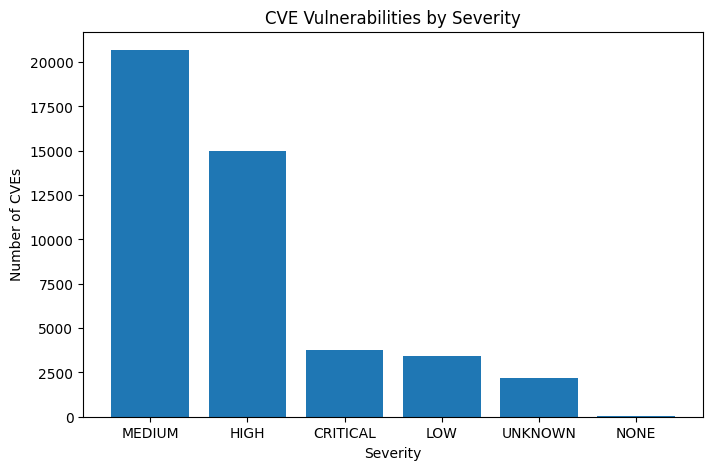

In [32]:
import matplotlib.pyplot as plt

severity = [
    x["_id"]
    for x in severity_results
]

counts = [
    x["count"]
    for x in severity_results
]

plt.figure(figsize=(8, 5))

plt.bar(severity,counts)

plt.xlabel("Severity")
plt.ylabel("Number of CVEs")
plt.title("CVE Vulnerabilities by Severity")

plt.show()

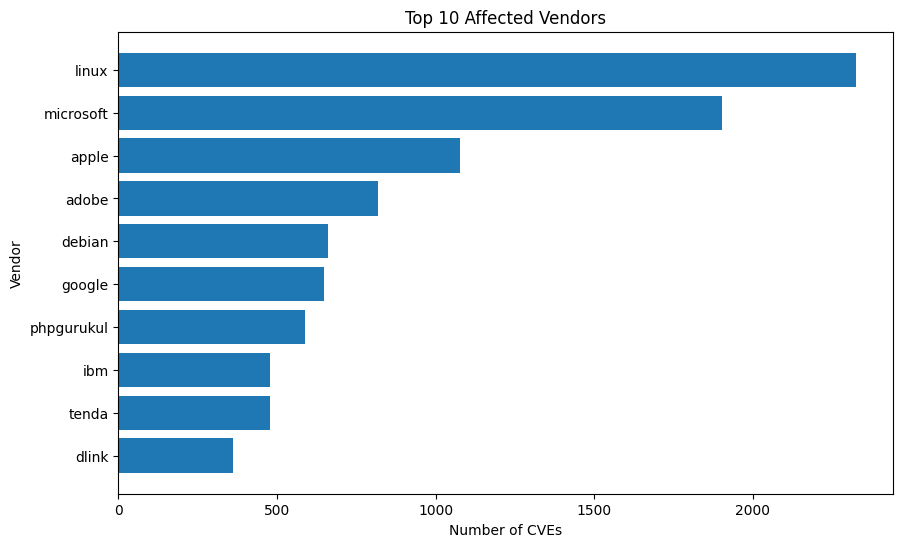

In [33]:
vendors = [
    x["_id"]
    for x in vendor_results
]

counts = [
    x["count"]
    for x in vendor_results
]

plt.figure(figsize=(10, 6))

plt.barh(vendors, counts)

plt.xlabel("Number of CVEs")
plt.ylabel("Vendor")
plt.title("Top 10 Affected Vendors")

plt.gca().invert_yaxis()

plt.show()

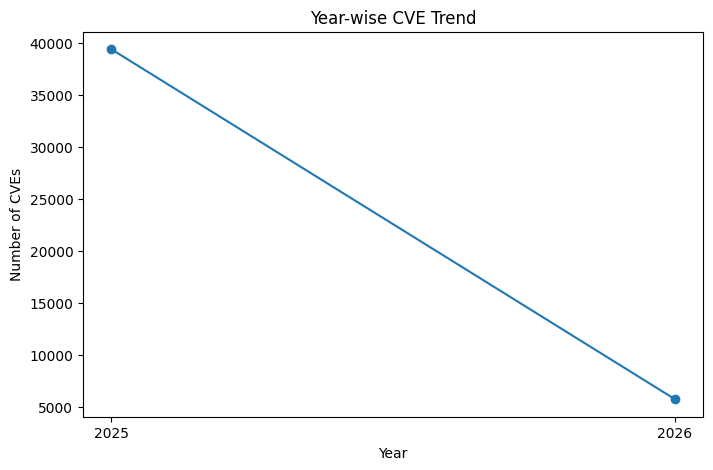

In [34]:
years = [
    x["_id"]
    for x in year_results
]

counts = [
    x["count"]
    for x in year_results
]

plt.figure(figsize=(8, 5))

plt.plot(
    years,
    counts,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of CVEs")
plt.title("Year-wise CVE Trend")

plt.show()

In [35]:
#avg cvss score spot1

pipeline = [
    {
        "$match": {
            "cvss_score": {
                "$ne": None
            }
        }
    },
    {
        "$project": {
            "year": {
                "$substr": ["$published", 0, 4]
            },
            "cvss_score": 1
        }
    },
    {
        "$group": {
            "_id": "$year",
            "average_cvss": {
                "$avg": "$cvss_score"
            }
        }
    },
    {
        "$sort": {
            "_id": 1
        }
    }
]

results = list(collection.aggregate(pipeline))

print("Average CVSS Score by Year\n")

for result in results:
    print(
        result["_id"],
        ":",
        round(result["average_cvss"], 2)
    )

Average CVSS Score by Year

2025 : 6.45
2026 : 6.74


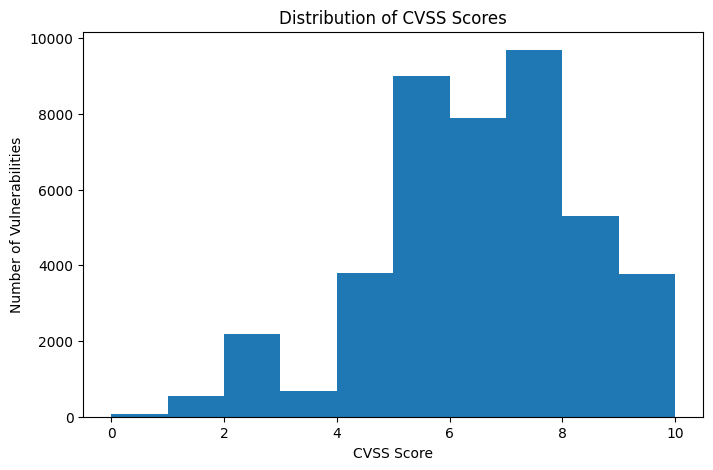

In [36]:
#distribution of cvss score

import matplotlib.pyplot as plt

scores = list(
    collection.find(
        {
            "cvss_score": {
                "$ne": None
            }
        },
        {
            "_id": 0,
            "cvss_score": 1
        }
    )
)

cvss_scores = [
    x["cvss_score"]
    for x in scores
]

plt.figure(figsize=(8, 5))

plt.hist(
    cvss_scores,
    bins=10
)

plt.xlabel("CVSS Score")
plt.ylabel("Number of Vulnerabilities")
plt.title("Distribution of CVSS Scores")

plt.show()

In [37]:
#vendor with high vulnerabilities

pipeline = [
    {
        "$unwind": "$vendors"
    },
    {
        "$group": {
            "_id": "$vendors",
            "vulnerability_count": {
                "$sum": 1
            }
        }
    },
    {
        "$sort": {
            "vulnerability_count": -1
        }
    },
    {
        "$limit": 1
    }
]

result = list(collection.aggregate(pipeline))

if result:
    print("Vendor with highest number of vulnerabilities:")
    print("Vendor:", result[0]["_id"])
    print(
        "Number of vulnerabilities:",
        result[0]["vulnerability_count"]
    )

Vendor with highest number of vulnerabilities:
Vendor: linux
Number of vulnerabilities: 2326
